<a href="https://colab.research.google.com/github/anderson-perez/IAC/blob/main/A2%20-%20Valida%C3%A7%C3%A3o%20e%20Avalia%C3%A7%C3%A3o%20de%20Modelos/Validacao_Modelos.ipynb" target="_blank">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/>
</a>

## Segunda Parte da Disciplina

# Informações:

- Prof. Anderson Luiz Fernandes Perez
- Contato: anderson.perez@ufsc.br | anderson.lfp@gmail.com
- Os materiais da disciplina estarão disponíveis no github (https://github.com/anderson-perez/IAC.git)

# Técnicas de Validação de Algoritmos de Aprendizado de Máquina

As técnicas de validação em aprendizado de máquina têm como principal objetivo estimar a capacidade de generalização de um modelo, isto é, verificar como ele se comporta diante de dados que não foram utilizados durante o treinamento.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Dataset de câncer de mama
from sklearn.datasets import load_breast_cancer

In [ ]:
#
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Métricas
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay, roc_auc_score)

In [ ]:
# Carrega o dataset
X, y = load_breast_cancer(return_X_y=True, as_frame=True)
print('Dimensões:', X.shape)
print('Distribuição das classes:\n', y.value_counts(normalize=True).round(3))

In [ ]:
# Instanciação dos modelos
lr = LogisticRegression()
knn = KNeighborsClassifier()
svm = SVC()

## Hold-Out: treinamento e teste

20% dos dados são utilizados como **teste final**. Os modelos e os hiperparâmetros serão comparados apenas com os 80% restantes. `stratify=y` mantém aproximadamente as proporções de classe.

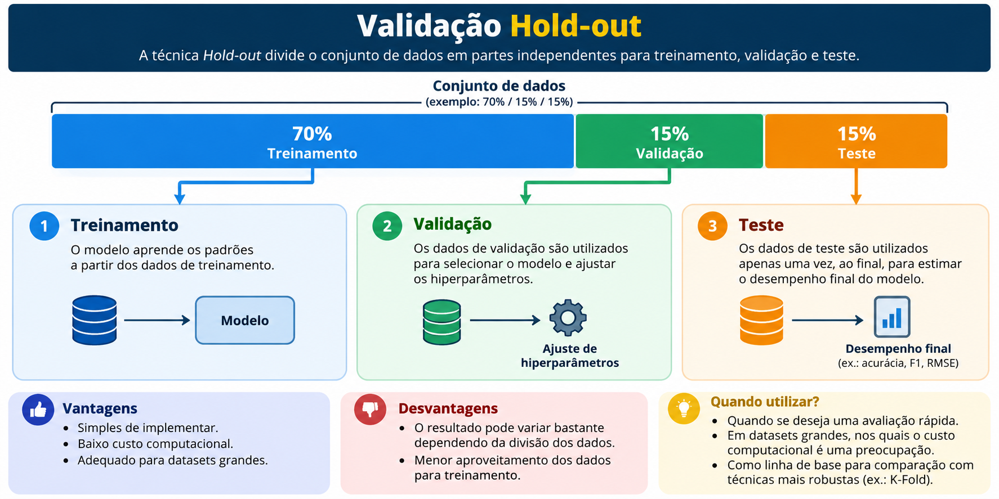

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
print('Treino:', X_treino.shape, '| Teste:', X_teste.shape)
print('Proporções (treino):', y_treino.value_counts(normalize=True).round(3).to_dict())
print('Proporções (teste):', y_teste.value_counts(normalize=True).round(3).to_dict())

## K-Fold Cros-Validation

Divide o dataset em $(K)$ partes (folds). O modelo é treinado $(K)$ vezes, utilizando uma parte diferente para validação em cada iteração.

O desempenho médio é calculado por:

$$
\overline{M}=\frac{1}{K}\sum_{i=1}^{K}M_i
$$

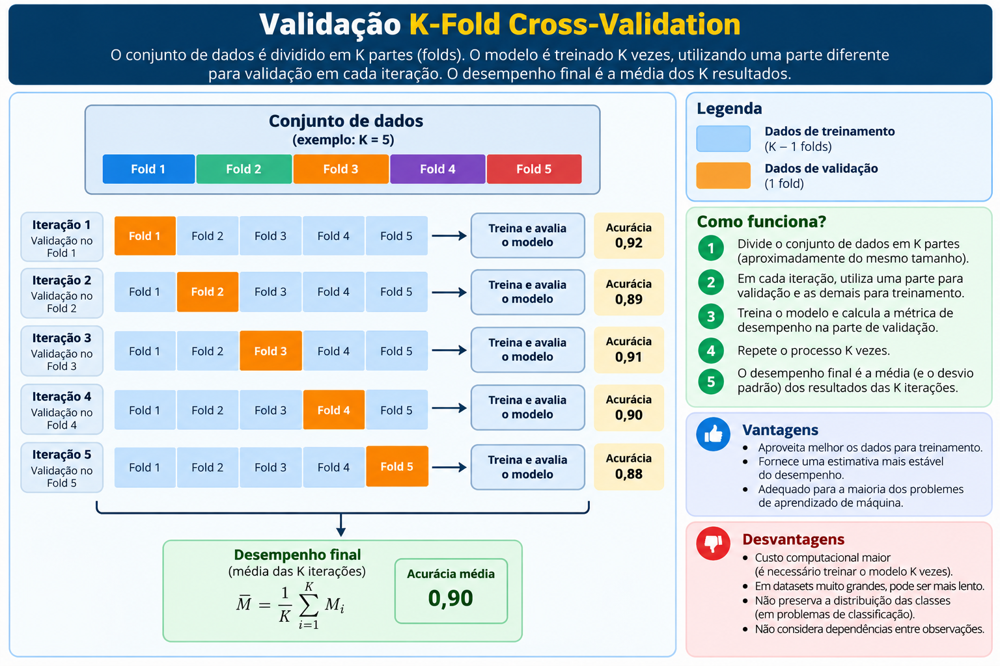

In [ ]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(knn, X_treino, y_treino, cv=cv)
print(scores.mean())

O `K-Fold Cros-Validation` exige treinar o modelo várias vezes

## Stratified K-Fold

É uma variação do `K-Fold` que preserva aproximadamente a proporção das classes em cada fold.

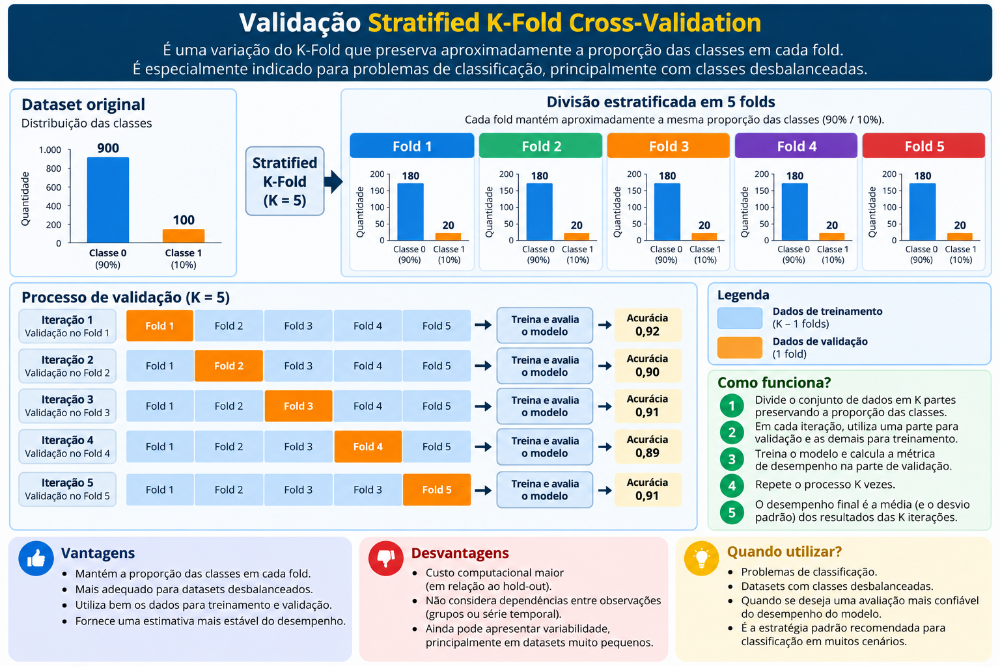

In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(knn, X_treino, y_treino, cv=cv)
print(scores.mean())

## Leave-One-Out Cross-Validation (LOOCV)

É um caso particular do K-Fold no qual:

$$
K=N
$$

Sendo $(N)$ o número de observações.

Em cada iteração, o modelo é treinado com $(N-1)$ observações e validado com apenas uma.

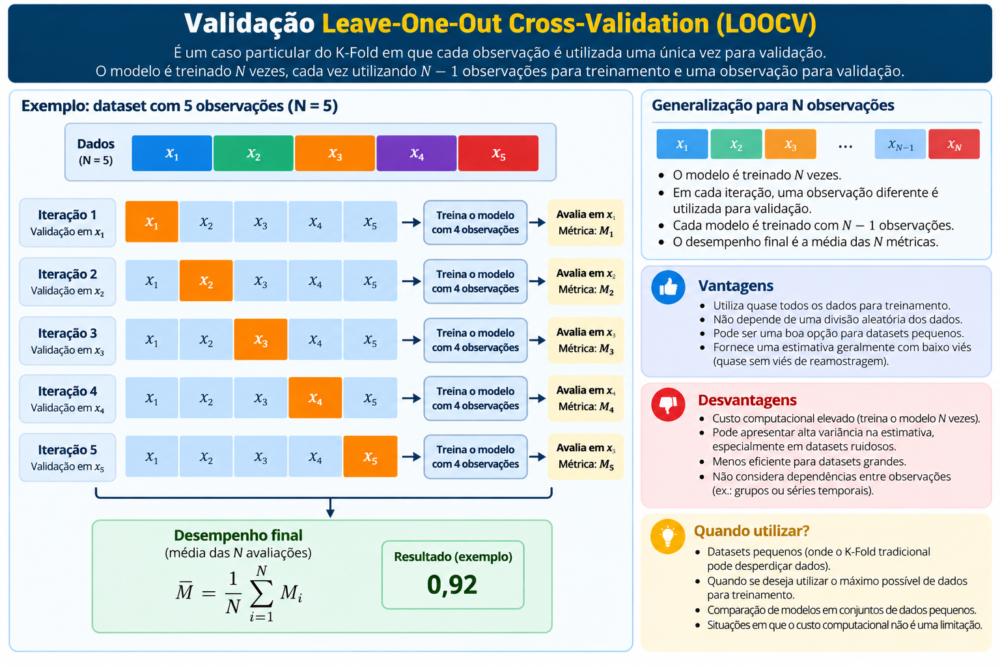

In [ ]:
from sklearn.model_selection import LeaveOneOut

cv = LeaveOneOut()

scores = cross_val_score(knn, X_treino, y_treino, cv=cv)
print(scores.mean())

A vantagem do `leaveoneout` é que ele utiliza quase todos os dados em cada treinamento. A desvantagem é que o custo computacional é muito elevado, especialmente para datasets grandes.

## Repeated K-Fold

Executa o K-Fold várias vezes, alterando a divisão dos dados entre as repetições. Por exemplo, um K-Fold de 5 partes repetido 10 vezes produz 50 avaliações.

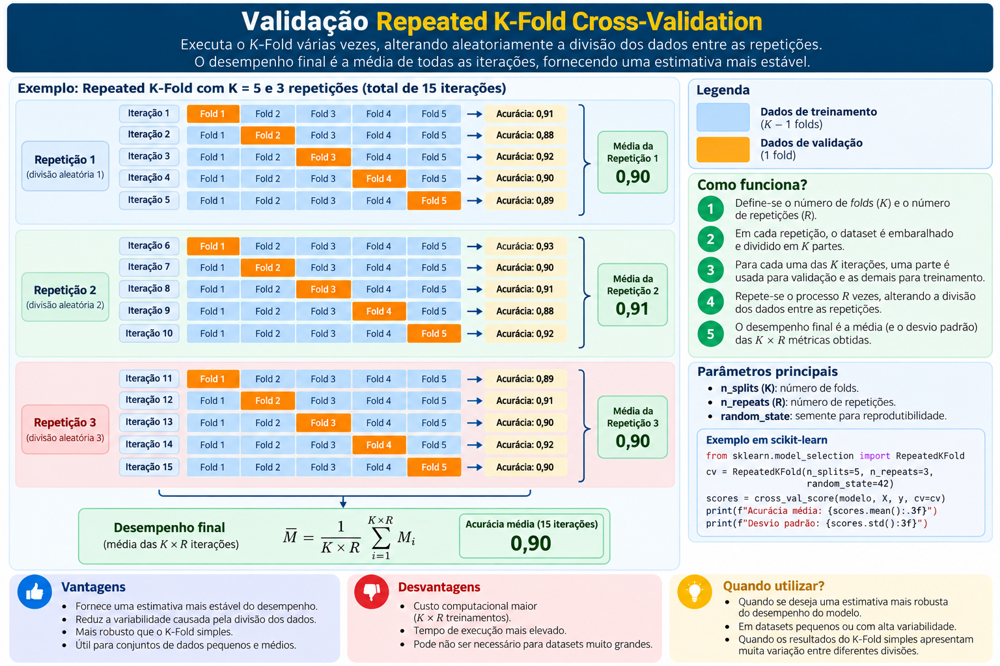

In [ ]:
from sklearn.model_selection import RepeatedKFold

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

scores = cross_val_score(knn, X_treino, y_treino, cv=cv)
print(scores.mean())

O `repeatedkfold` é útil para avaliar a sensibilidade do modelo às diferentes divisões dos dados.

## Group K-Fold

Utilizado quando as observações pertencem a grupos e não devem ser distribuídas entre treinamento e validação.

Se diferentes observações vêm da mesma observação, misturá-las entre treino e validação pode superestimar a capacidade de generalização. `GroupKFold` evita a presença de um mesmo grupo em ambos os conjuntos.

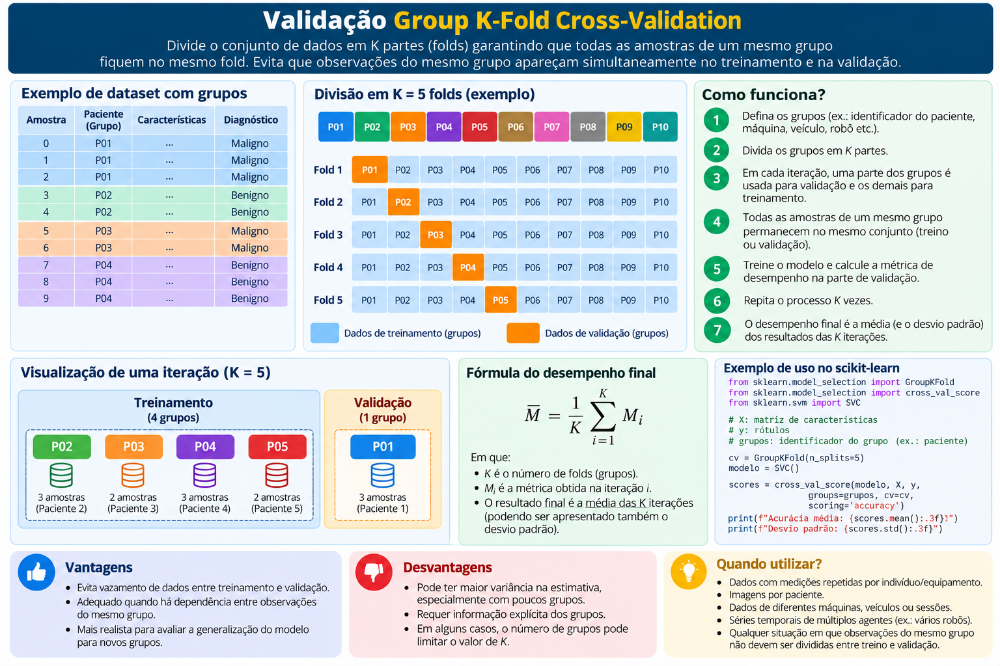

In [ ]:
# Cria grupos
grupos = np.arange(len(y_treino)) // 5

In [ ]:
from sklearn.model_selection import GroupKFold

cv = GroupKFold(n_splits=5)

scores = cross_val_score(knn, X_treino, y_treino, groups=grupos, cv=cv)
print(scores.mean())

# Otimização de Hiperparâmetros

A otimização de hiperparâmetros consiste em encontrar a combinação de hiperparâmetros que proporciona o melhor desempenho de generalização de um modelo de aprendizado de máquina.

Algumas técnicas utilizadas para otimizar os hiperparâmetros são:

```text
* Grid Search
* Random Search
* Algoritmos Genéticos
* Particle Swarm Optmization (PSO)
```

## Grid Search

Testa sistematicamente todas as combinações de valores previamente especificados.

In [ ]:
from sklearn.model_selection import GridSearchCV

parametros = {
    'n_neighbors': range(1, 31)
}

grid = GridSearchCV(
    knn,
    parametros,
    cv=5,
    scoring='accuracy'
)

grid.fit(X_treino, y_treino)

print("Melhor K:", grid.best_params_)
print("Melhor acurácia:", grid.best_score_)

## Random Search

O Random Search seleciona aleatoriamente combinações de hiperparâmetros dentro de um espaço de busca.

Ao contrário do Grid Search, não precisa testar todas as combinações.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

parametros = {
    'n_neighbors': range(1, 31),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}


random_search = RandomizedSearchCV(
    estimator=knn,
    param_distributions=parametros,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_treino, y_treino)

print("Melhores hiperparâmetros: ")
print(random_search.best_params_)

print("Melhor acurácia na validação: ")
print(random_search.best_score_)